# 3. Fourier transform: images as spatial frequencies

An image can be described in two complementary ways: by the pixel values at each location (the **spatial representation**) or by the strength of patterns at different frequencies (the **frequency representation**). The Fourier transform changes between these descriptions.

In this notebook, we will see how a spatial operator `A` is represented in the frequency basis:

$$A = F^\dagger \widehat{A} F$$

Here, `F` maps spatial coordinates to frequency coordinates, `F†` maps back, and `Â` is the same operation expressed in the frequency basis. We will then remove low or high frequencies from a real image and compare the results.

## 1. A change of basis for an operator

For an `N`-element signal, use the unitary discrete Fourier matrix

$$F_{k,n} = \frac{1}{\sqrt{N}}e^{-2\pi i kn/N}, \qquad k,n=0,\ldots,N-1.$$

The rows of `F` are frequency patterns: multiplying by `F` computes how much of each pattern is present. Its conjugate transpose `F†` is its inverse. If `x` is a spatial signal, its frequency coordinates are `x̂ = F*x`. An operator `A` acts in space as `y = A*x`; in frequency coordinates the same operation is `ŷ = Â*x̂`, where `Â = F*A*F†`. Rearranging gives `A = F†*Â*F`.

We will check this with a small circular blur. Such a blur is diagonal in the Fourier basis: each frequency is scaled independently.

In [1]:
using LinearAlgebra
using FFTW

N = 8
F = [cis(-2π * k * n / N) / sqrt(N) for k in 0:N-1, n in 0:N-1]
shift = [i == mod1(j + 1, N) ? 1.0 : 0.0 for i in 1:N, j in 1:N]
A = (shift + 2I + shift') / 4
A_hat = F * A * F'

off_diagonal = A_hat - Diagonal(diag(A_hat))
spatial_signal = [0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0]
spatial_result = A * spatial_signal
frequency_result = F' * (A_hat * (F * spatial_signal))
(maximum(abs, off_diagonal), norm(spatial_result - frequency_result))

(4.269139294090101e-16, 1.5963646384986927e-15)

Both numbers should be close to zero (up to floating-point rounding). The first confirms that the blur operator is diagonal in the Fourier basis; the second confirms `A*x = F†*Â*F*x`. The diagonal entries of `Â` tell us how strongly the blur keeps or attenuates each frequency.

## 2. Look at an image's frequency representation

A two-dimensional Fourier transform has one frequency coordinate for each image direction. First, display the original color image. Then we will convert it to grayscale for the frequency analysis. In the spectrum display, low frequencies are moved to the center; farther from the center means finer spatial detail. Brightness shows the logarithm of the frequency magnitude, since the values can vary greatly in scale.

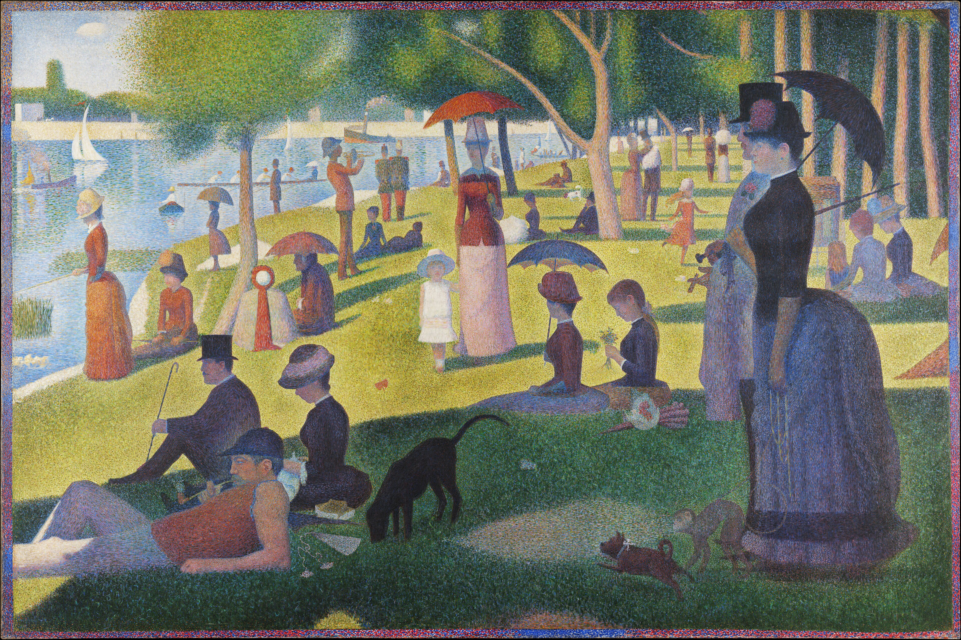

In [2]:
using Images
using ImageIO

image_path = joinpath(@__DIR__, "..", "images", "sunday-la-grande-jatte.jpg")
img = load(image_path)


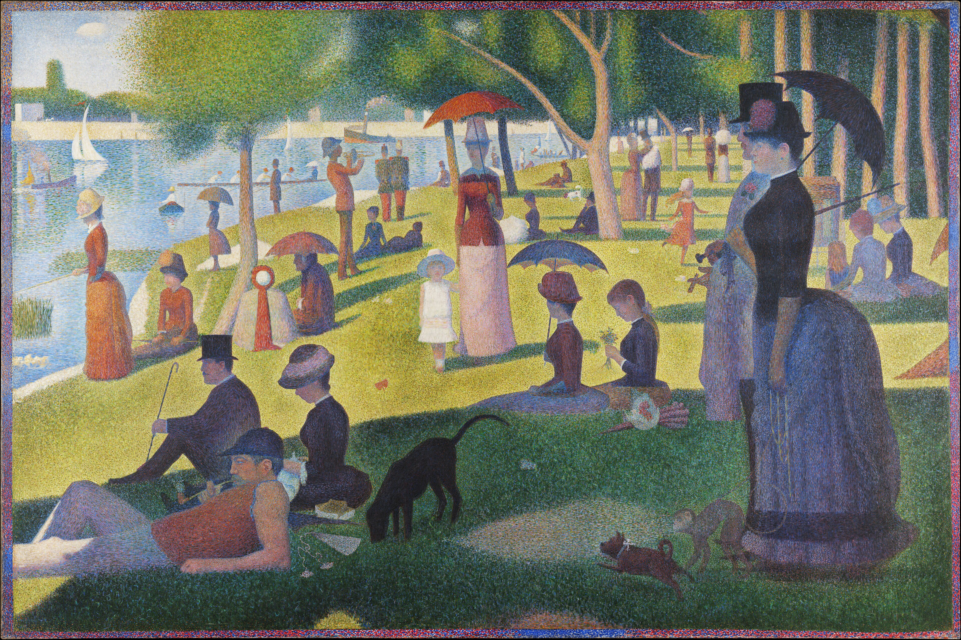

In [3]:
img

In [4]:
gray_image = Float64.(Gray.(img))
size(gray_image)

(2556, 3840)

In [5]:
gray_image

2556×3840 Matrix{Float64}:
 0.0         0.0117647   0.0156863   …  0.00392157  0.00784314  0.0117647
 0.00392157  0.00784314  0.192157       0.00392157  0.0117647   0.0196078
 0.00784314  0.0901961   0.713725       0.0         0.00392157  0.00784314
 0.0117647   0.423529    0.564706       0.0392157   0.00392157  0.00392157
 0.0352941   0.647059    0.486275       0.0117647   0.00784314  0.00784314
 0.0431373   0.596078    0.54902     …  0.368627    0.00784314  0.0235294
 0.117647    0.607843    0.486275       0.752941    0.121569    0.00784314
 0.301961    0.52549     0.278431       0.588235    0.396078    0.0156863
 0.407843    0.541176    0.317647       0.545098    0.505882    0.00784314
 0.396078    0.560784    0.647059       0.631373    0.65098     0.027451
 ⋮                                   ⋱                          
 0.458824    0.654902    0.341176       0.396078    0.72549     0.447059
 0.192157    0.615686    0.254902       0.52549     0.752941    0.388235
 0.0117647   0.537

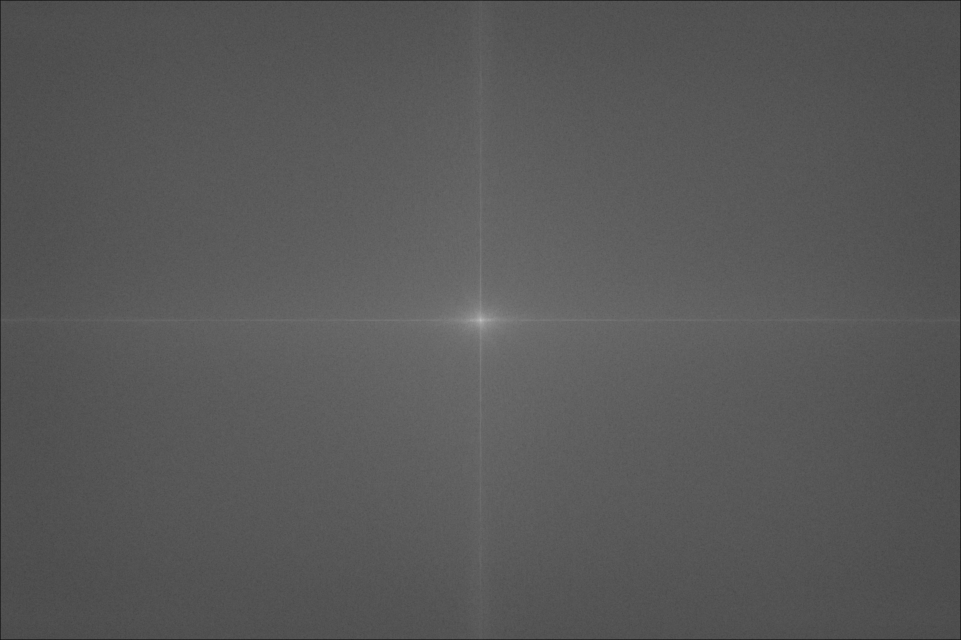

In [6]:
spectrum = fft(gray_image)
centered_spectrum = circshift(spectrum, (size(spectrum, 1) ÷ 2, size(spectrum, 2) ÷ 2))
log_magnitude = log1p.(abs.(centered_spectrum))
Gray.(log_magnitude ./ maximum(log_magnitude))

The center contains the average brightness and other slowly changing structures. Fine edges, texture, and abrupt pixel changes contribute to frequencies farther from the center. The Fourier transform itself does not change the image; it changes the basis used to describe it.

## 3. Remove high frequencies: low-pass filtering

A low-pass filter keeps frequencies near zero and removes those above a chosen radial cutoff. This suppresses fine details and makes the image look smoother. The FFT frequency coordinates below are measured in cycles per pixel.

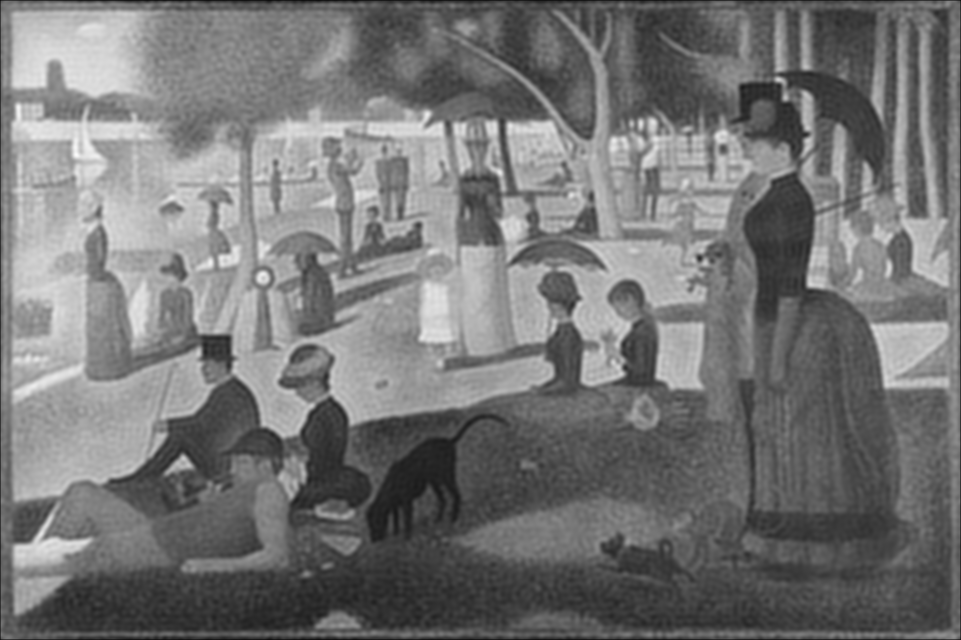

In [7]:
height, width = size(gray_image)
signed_frequency(index, length) = index - 1 <= fld(length, 2) ? (index - 1) / length : (index - 1 - length) / length
frequency_radius = [hypot(signed_frequency(row, height), signed_frequency(col, width)) for row in 1:height, col in 1:width]

cutoff = 0.035
low_pass_mask = frequency_radius .<= cutoff
low_pass = real.(ifft(spectrum .* low_pass_mask))
Gray.(clamp.(low_pass, 0, 1))

This keeps broad shapes and gradual changes while attenuating sharp edges and texture. The cutoff is in cycles per pixel; lowering it retains fewer frequencies and produces more blur. The result is clamped to the display range `[0, 1]`.

## 4. Remove low frequencies: high-pass filtering

A high-pass filter does the opposite: it removes the low frequencies and keeps the finer variations. Since the filtered values are centered around zero rather than being ordinary brightness values, we add mid-gray and boost contrast for display. This display adjustment is only for visualization; `high_pass` holds the actual filtered values.

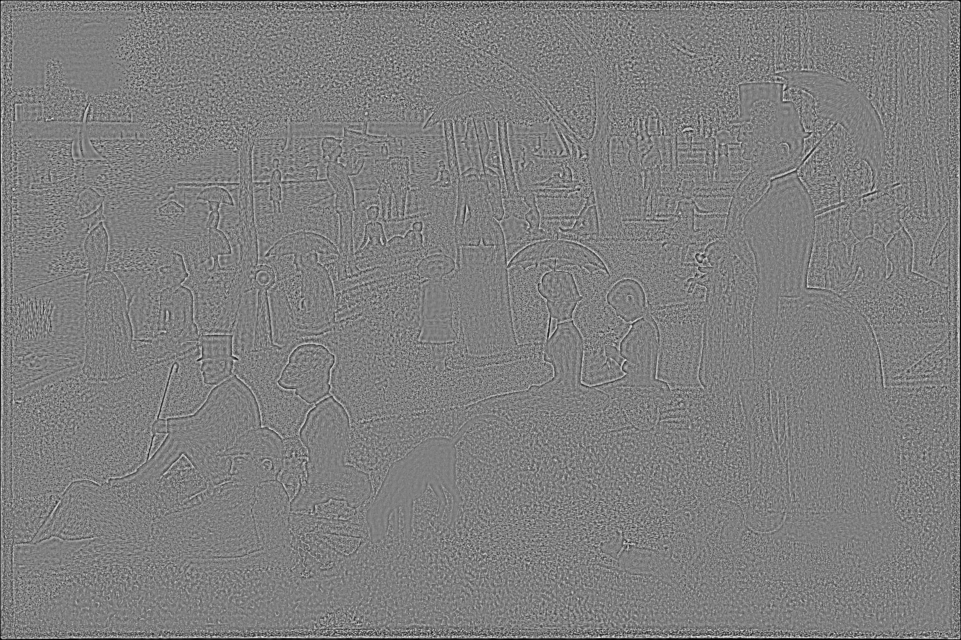

In [8]:
high_pass_mask = frequency_radius .> cutoff
high_pass = real.(ifft(spectrum .* high_pass_mask))
Gray.(clamp.(0.5 .+ 2 .* high_pass, 0, 1))

The high-pass result emphasizes edges and texture, while large smooth regions fade toward gray. Compare it with the low-pass result: the two filters retain complementary parts of the image's frequency content.

## Your turn

1. Change `cutoff` and rerun the filter cells. How does each result change?
2. Reconstruct the image by adding `low_pass` and `high_pass`. Why do they add back to the original (apart from floating-point error)?
3. In `A_hat`, inspect the diagonal. Which frequencies does the circular blur attenuate most?
4. What might happen if you keep only a band of frequencies between two cutoffs?

The masks here are ideal hard cutoffs, which can create ringing artifacts near sharp edges. Smoothly tapering the mask is one way to reduce them.